In [24]:
import pandas as pd

from data_inspection import DataInspector, InspectingDatatypesStrategy, InspectingSummaryStatistics
from missing_values_analysis import MissingValuesReport
from univariate_analysis import UnivariateAnalysisExecutor, UnivariateNumericalAnalysis, UnivariateCategoricalAnalysis
from bivariate_analysis import BivariateAnalysisExecutor, NumericalWithNumericalAnalysis, CategoricalWithNumericalAnalysis
from multivariate_analysis import SimpleMultivariateStatisticalAnalysis


In [25]:
data_path = '../data_source/crop_dataset.csv'
df = pd.read_csv(data_path)

In [26]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [27]:
data_inspector = DataInspector(InspectingDatatypesStrategy())
data_inspector.run_inspection(df)


Count of data types and non-null elements:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2404 entries, 0 to 2403
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2404 non-null   int64  
 1   P            2404 non-null   int64  
 2   K            2404 non-null   int64  
 3   temperature  2404 non-null   float64
 4   humidity     2404 non-null   float64
 5   ph           2404 non-null   float64
 6   rainfall     2404 non-null   float64
 7   label        2404 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 150.4+ KB
None


In [28]:
data_inspector.configure_strategy(InspectingSummaryStatistics())
data_inspector.run_inspection(df)


Statistical Summary of numerical features:
                 N            P            K  temperature     humidity  \
count  2404.000000  2404.000000  2404.000000  2404.000000  2404.000000   
mean     54.079035    53.799501    49.737105    25.594094    71.331026   
std      37.528344    32.024461    49.027012     5.107935    21.555711   
min       0.000000     5.000000     5.000000     8.825675    14.258040   
25%      22.000000    30.000000    21.000000    22.616237    60.176664   
50%      40.000000    52.000000    35.000000    25.611339    79.995776   
75%      89.000000    69.000000    52.000000    28.618342    88.956957   
max     140.000000   145.000000   205.000000    43.675493    99.981876   

                ph     rainfall  
count  2404.000000  2404.000000  
mean      6.469279   112.229651  
std       0.760670    62.212261  
min       3.504752    20.211267  
25%       5.971114    66.480706  
50%       6.425675   100.529575  
75%       6.929842   148.319557  
max       9.93509

## Data inspection report

### 1. Dataset Overview
- The dataset consists of **2404 records** and **8 columns**.
- It contains **3 integer features (N, P, K)**, **4 float features (temperature, humidity, ph, rainfall)**, and **1 categorical feature (label)**.

### 2. Memory Usage
- The dataset takes approximately **150.4 KB** in memory.

### 3. Summary Statistics
#### Numerical Features
- **Nitrogen (N)**: Mean = 54.08, Std = 37.53, Min = 0, Max = 140
- **Phosphorus (P)**: Mean = 53.80, Std = 32.02, Min = 5, Max = 145
- **Potassium (K)**: Mean = 49.74, Std = 49.03, Min = 5, Max = 205
- **Temperature**: Mean = 25.59°C, Std = 5.11, Min = 8.83, Max = 43.68
- **Humidity**: Mean = 71.33%, Std = 21.56, Min = 14.26, Max = 99.98
- **pH Level**: Mean = 6.47, Std = 0.76, Min = 3.50, Max = 9.94
- **Rainfall**: Mean = 112.23 mm, Std = 62.21, Min = 20.21, Max = 299.84

#### Categorical Feature
- **Label**: 23 unique categories
- Most frequent crop: **Corn (200 occurrences)**

### 4. Observations
- The distribution of N, P, and K varies significantly, indicating different soil fertility levels.
- Temperature and humidity show expected natural variations.
- Rainfall values range widely, suggesting diverse climatic conditions in the dataset.
- The pH values mostly stay within the optimal range for crop growth but have some outliers.
- Some crops appear more frequently than others, which might affect model training if used for classification.

In [29]:
missing_values_processor = MissingValuesReport()
missing_values_processor.missing_values_analysis(df)


Missing Values Count by Column:
No missing values found.

No missing values to visualize.


## Missing Values Report

### 1. Missing Values
- There are 2405 records and no **missing values** found
- The dataset is completely clean and there will be no need of any other additional strategies to be performed on the dataset in case of missing data values

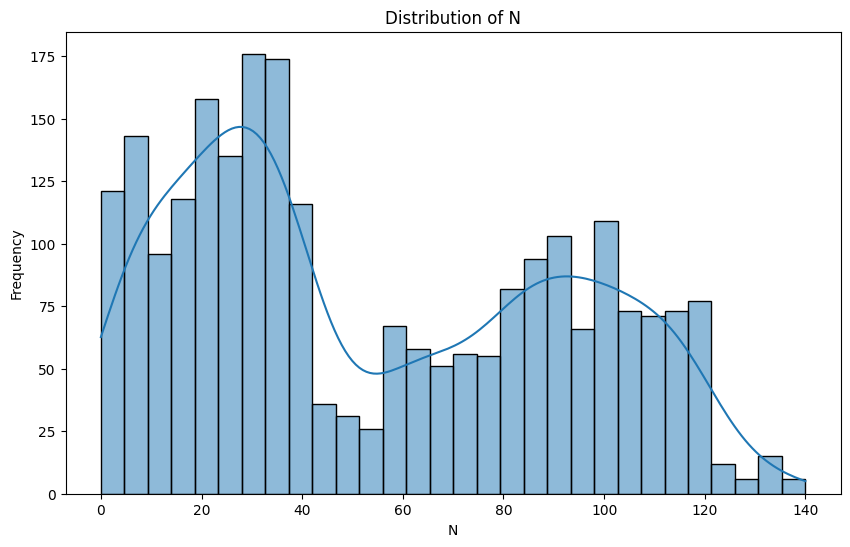

In [30]:
univariate_processor = UnivariateAnalysisExecutor(UnivariateNumericalAnalysis())
univariate_processor.run_analysis(df, 'N')

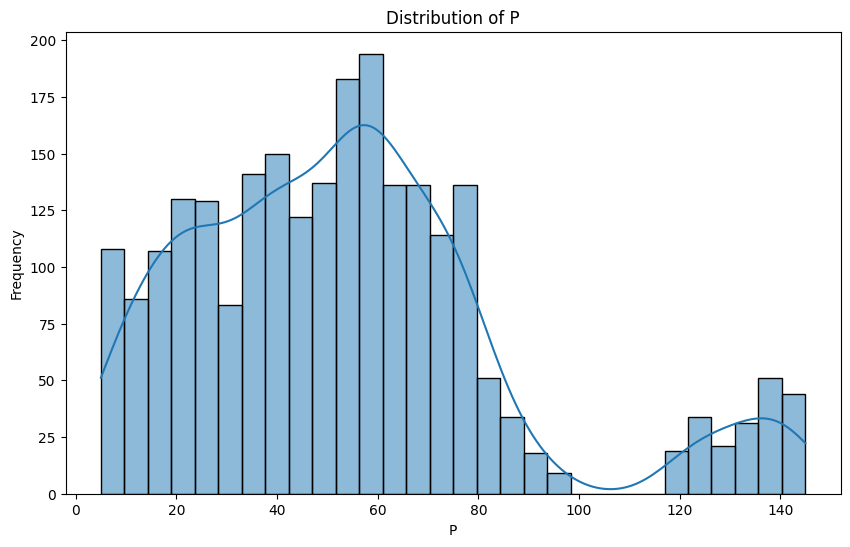

In [31]:
univariate_processor.run_analysis(df, 'P')

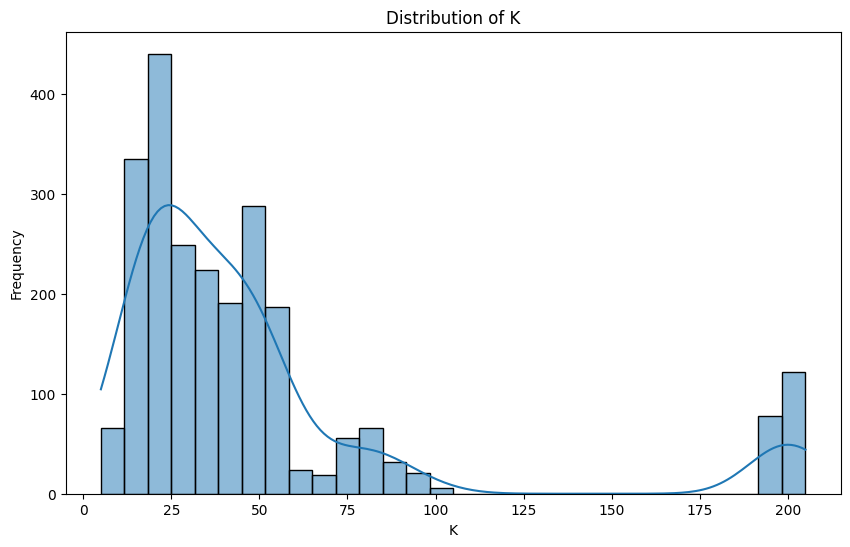

In [32]:
univariate_processor.run_analysis(df, 'K')

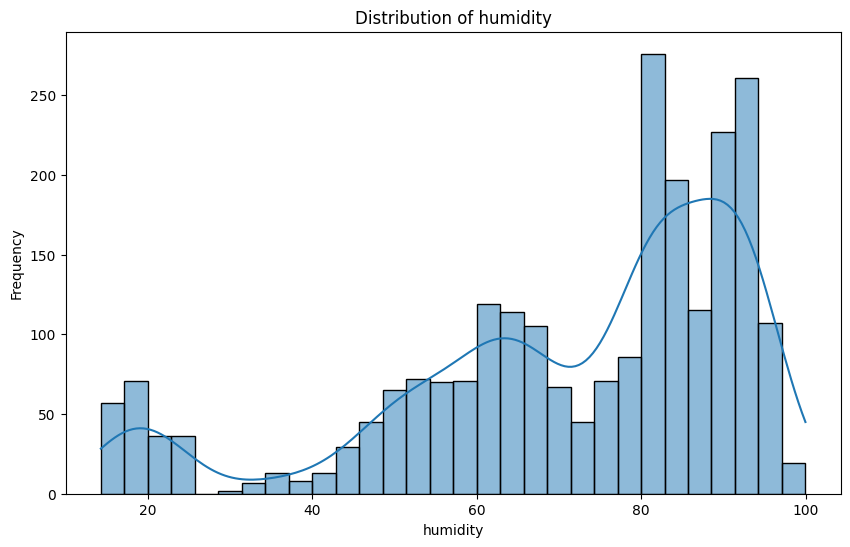

In [33]:
univariate_processor.run_analysis(df, 'humidity')

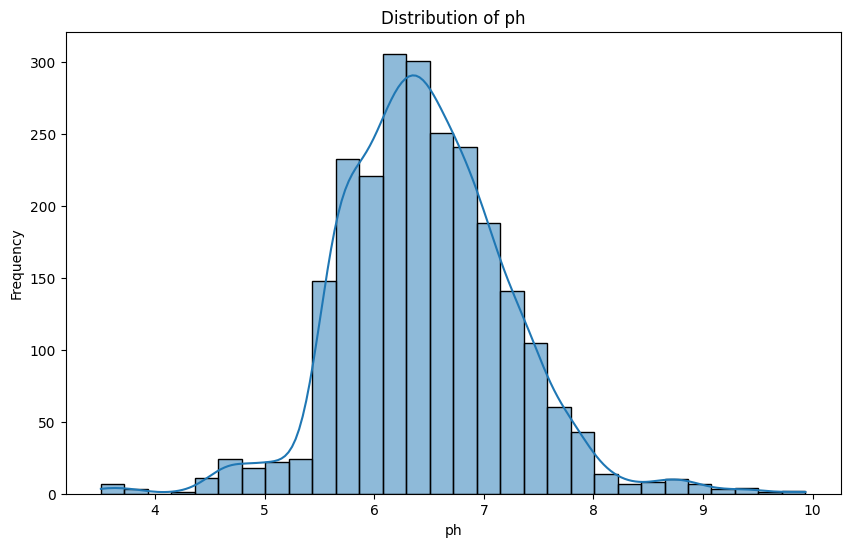

In [34]:
univariate_processor.run_analysis(df, 'ph')

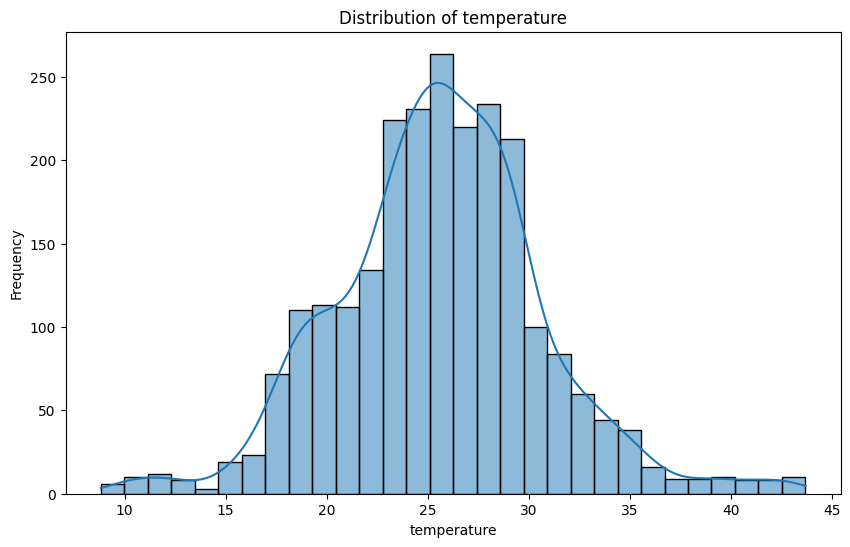

In [35]:
univariate_processor.run_analysis(df, 'temperature')

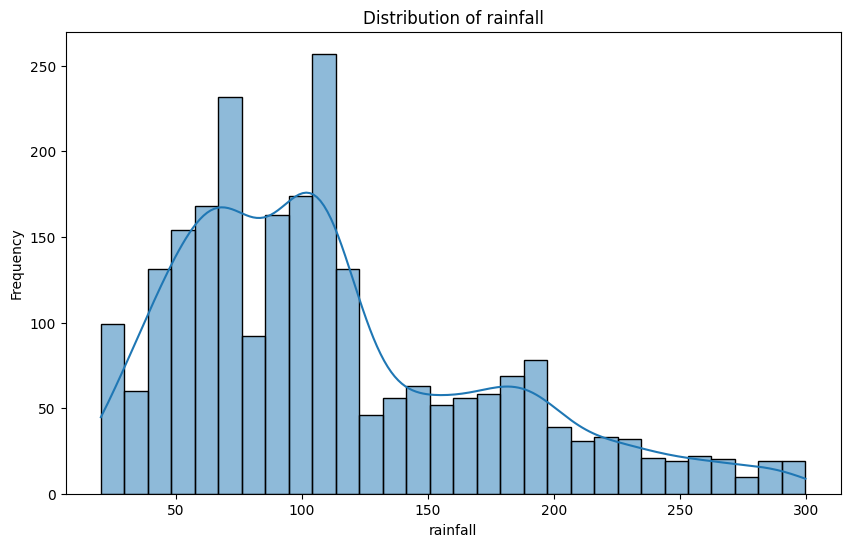

In [36]:
univariate_processor.run_analysis(df, 'rainfall')

c:\Users\kanak\OneDrive\文档\Personal Projects\smart-agri-tech\src\eda\univariate_analysis.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=feature, data=df, palette="muted")


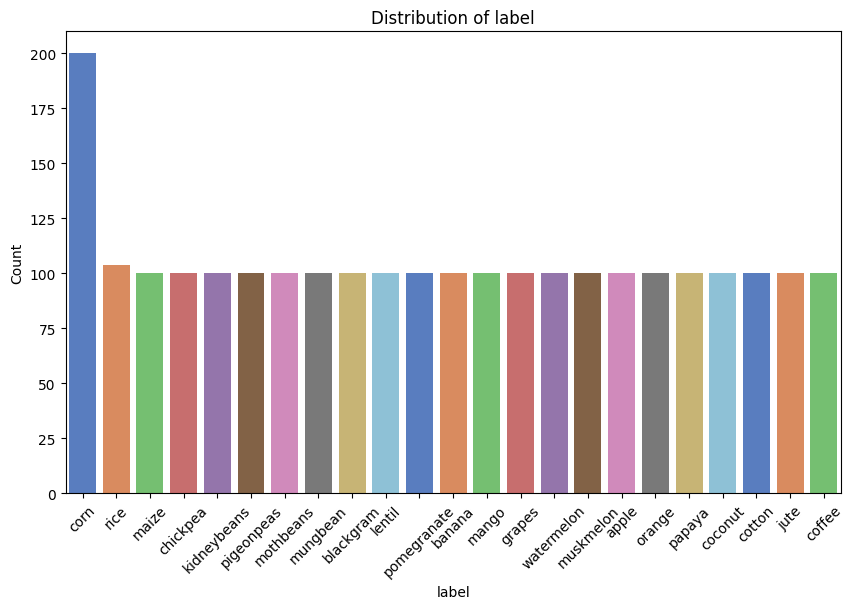

In [37]:
univariate_processor.configure_strategy(UnivariateCategoricalAnalysis())
univariate_processor.run_analysis(df, 'label')

#  **Univariate Analysis Report on Crop Growth Factors**

##  **1. Nitrogen (N) - The Growth Catalyst**
###  **Observations:**
- The nitrogen levels in the dataset appear **stable** over time.
- The frequency distribution shows a **rise at higher values**, followed by a decline, and then stabilization at an average level.

###  **Insights & Implications:**
- **Stable nitrogen levels** indicate that farmers might be applying fertilizers consistently.
- Since nitrogen plays a key role in **leaf and stem growth**, maintaining adequate levels is **critical for optimal crop yield**.
- Any fluctuations in nitrogen availability could lead to **stunted growth or excessive vegetative growth** (at very high levels).
- **Recommendation:** Regular soil testing is needed to maintain balanced nitrogen levels.



##  **2. Phosphorus (P) - Root Development Booster**
###  **Observations:**
- **For X-axis range 0-100:** At least **10 frequency is required** for growth.
- **For X-axis range 50-70:** The frequency exceeds **175**, indicating high phosphorus uptake.                 

###  **Insights & Implications:**
- Phosphorus is essential for **root development and early plant establishment**.
- The high frequency in the **50-70 range** suggests that this is the **optimal phosphorus level** for most crops.
- **Deficiency risks:** Insufficient phosphorus may lead to **poor root growth, delayed maturity, and reduced yield**.
- **Recommendation:** Farmers should aim for a phosphorus range of **50-70** for maximum productivity.



##  **3. Potassium (K) - The Yield Enhancer**
###  **Observations:**
- **No significant frequency for values in the lower half** of the data.
- **For some crops:** More than **400 frequency** is required.

###  **Insights & Implications:**
- Potassium is vital for **water regulation, enzyme activation, and disease resistance**.
- The high requirement for **certain crops (400+ frequency)** suggests that potassium is a **limiting factor** for their growth.
- **Deficiency risks:** Crops lacking potassium may show **scorched leaf tips, weak stems, and poor resistance to drought**.
- **Recommendation:** Farmers should focus on crops that naturally require **higher potassium intake** and adjust fertilization accordingly.



##  **4. Humidity - The Climate Controller**
###  **Observations:**
- **For X-axis range 80-100:** Frequency exceeds **150**.

###  **Insights & Implications:**
- High humidity levels are often associated with **better crop growth**, especially for **tropical and moisture-loving plants**.
- However, excessive humidity can promote **fungal diseases** and reduce photosynthetic efficiency.
- **Recommendation:** Proper irrigation management and ventilation are necessary to **balance moisture levels** for different crop types.



##  **5. pH - The Soil’s Chemical Balance**
###  **Observations:**
- **For pH range 0-5:** Frequency remains **below 25**.
- **For pH range 5.5-8.0:** Frequency **scales above 300**, with an **average of 150**.

###  **Insights & Implications:**
- Most crops thrive in a **slightly acidic to neutral pH (5.5-7.0)**.
- A pH below **5** indicates **acidic soil conditions**, which may hinder nutrient absorption.
- **Alkaline soils (>8.0) may lead to nutrient lockout**, affecting growth.
- **Recommendation:** Lime can be used to increase soil pH, while sulfur-based amendments can lower it.



##  **6. Temperature - The Growth Regulator**
### 🔍 **Observations:**
- **For 0-15°C:** Frequency does not exceed **25**.
- **For 25-30°C:** This range is **optimal**, with frequency **peaking beyond 200**.
- **For 35-45°C:** Growth declines significantly (**frequency < 50**).

###  **Insights & Implications:**
- Crops prefer a **moderate temperature range (25-30°C)** for **optimal enzymatic activity** and **photosynthesis**.
- **Extreme temperatures (below 15°C or above 35°C) reduce productivity**, likely due to stress and **reduced metabolic activity**.
- **Recommendation:** Farmers should choose crop varieties suited to their **local temperature ranges** and consider **shade nets or irrigation cooling systems** for temperature-sensitive crops.



##  **7. Rainfall - The Lifeline of Agriculture**
###  **Observations:**
- **For X-axis range 0-110 mm:** High frequency.
- **For X-axis range 200-300 mm:** Frequency drops **below 50**.

###  **Insights & Implications:**
- Crops seem to thrive best **under moderate rainfall conditions (0-110 mm)**.
- Higher rainfall levels **(200-300 mm)** show **reduced frequency**, indicating potential issues like **waterlogging or nutrient leaching**.
- **Recommendation:** 
  - For high-rainfall regions, **drainage management and soil structure improvements** are crucial.
  - For low-rainfall regions, **drought-resistant crops and efficient irrigation systems** should be considered.


#  **Final Takeaways & Recommendations**
 **Nitrogen, phosphorus, and potassium levels should be optimized to enhance plant growth.**  
 **Humidity and temperature significantly impact crop productivity, with optimal conditions favoring higher yields.**  
 **Soil pH must be maintained between 5.5-8.0 for balanced nutrient absorption.**  
  **Rainfall variations highlight the need for proper water management strategies.**  


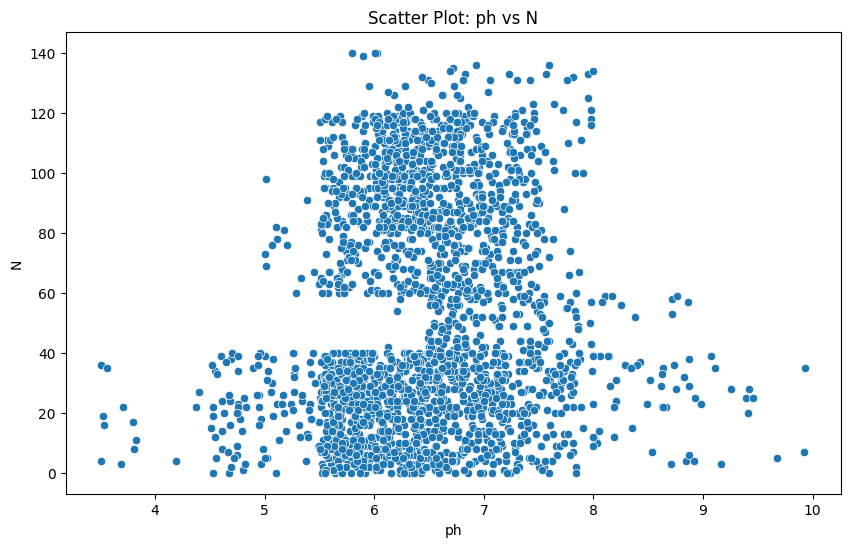

In [38]:
bivariate_processor = BivariateAnalysisExecutor(NumericalWithNumericalAnalysis())
bivariate_processor.run_analysis(df, 'ph', 'N')


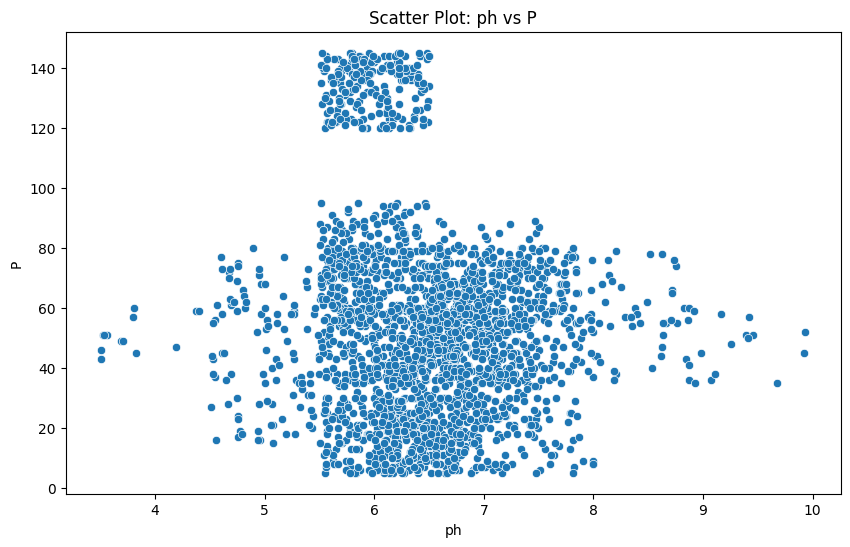

In [39]:
bivariate_processor.run_analysis(df, 'ph', 'P')

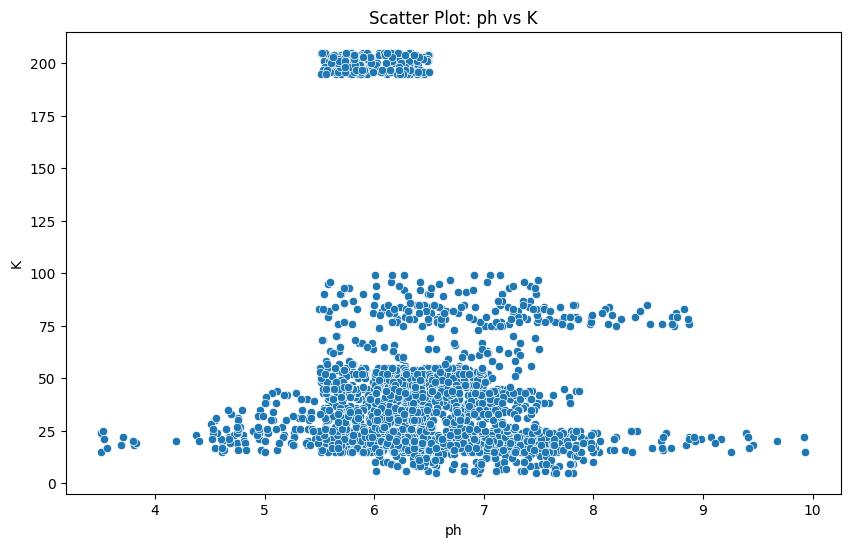

In [40]:
bivariate_processor.run_analysis(df, 'ph', 'K')


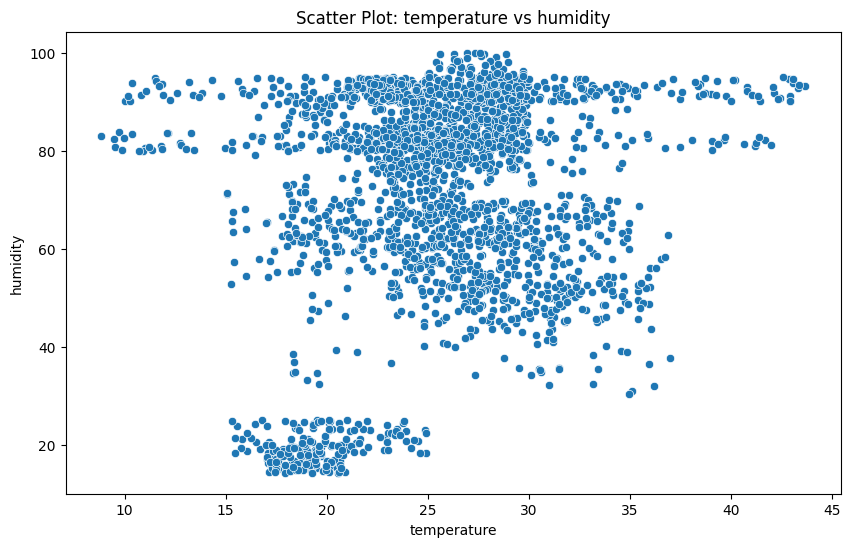

In [41]:
bivariate_processor.run_analysis(df, 'temperature', 'humidity')

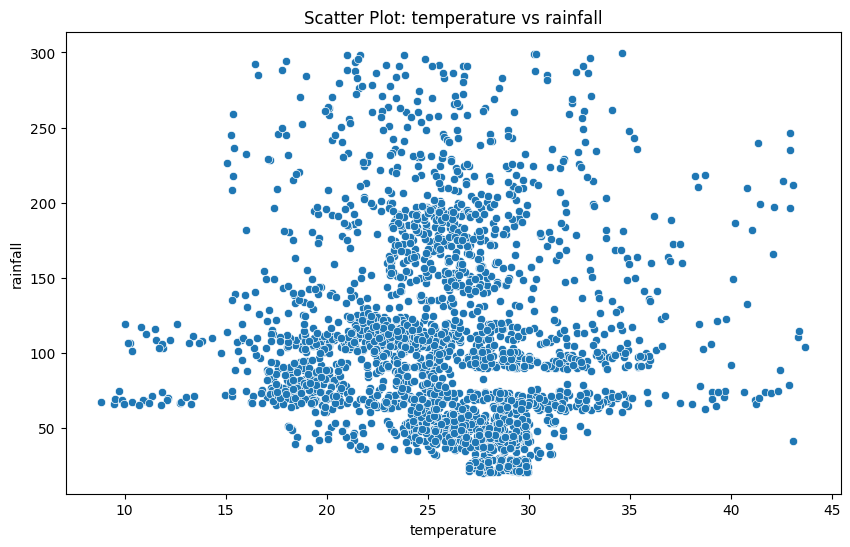

In [42]:
bivariate_processor.run_analysis(df, 'temperature', 'rainfall')

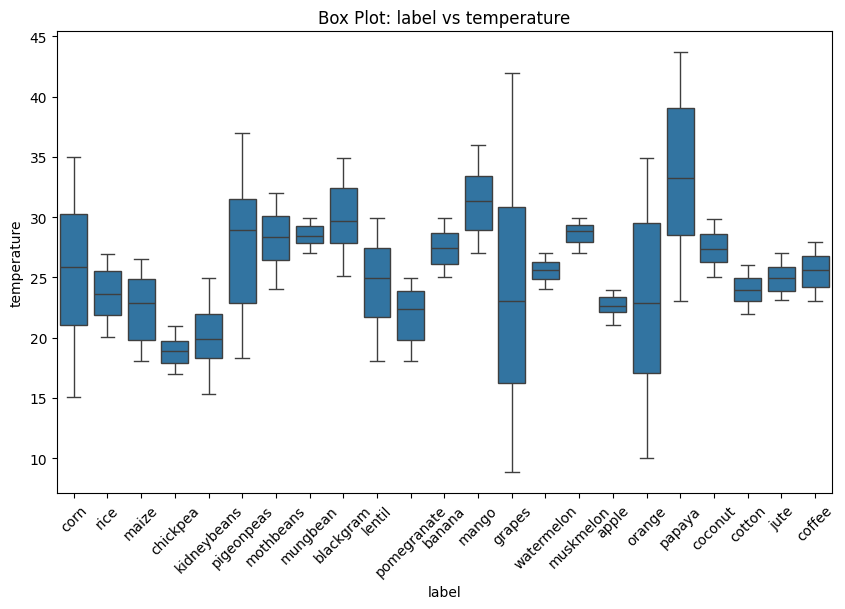

In [43]:
bivariate_processor.configure_strategy(CategoricalWithNumericalAnalysis())
bivariate_processor.run_analysis(df, 'label', 'temperature')

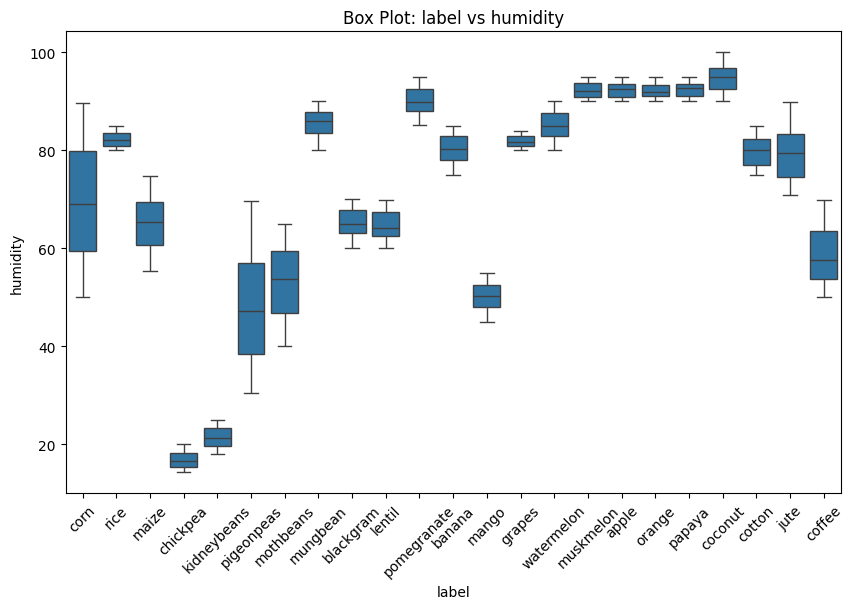

In [44]:
bivariate_processor.run_analysis(df, 'label', 'humidity')

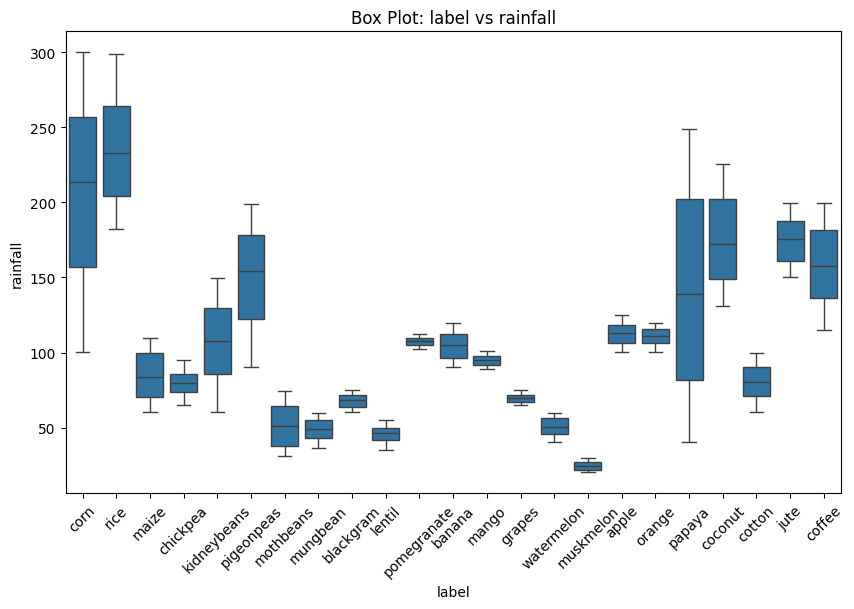

In [45]:
bivariate_processor.run_analysis(df, 'label', 'rainfall')

# Bivariate Analysis

## Scatter Plot Analysis

### 1. pH vs Nitrogen (N)
- **Observation:** The data points show moderate dispersion, indicating a varying but not strongly correlated relationship between soil pH and nitrogen levels.
- **Implication:** Nitrogen availability might be moderately influenced by pH but not in a strictly linear manner. Farmers should monitor soil pH to optimize nitrogen uptake.

### 2. pH vs Phosphorus (P)
- **Observation:** Most values are coupled, but a small cluster forms around pH 6-7 and P 120-140.
- **Implication:** This cluster suggests anomalous phosphorus absorption at neutral pH levels, possibly due to soil composition or fertilizer application.

### 3. pH vs Potassium (K)
- **Observation:** A stronger coupled dispersion compared to the previous two, with a separate cluster at pH 5.5-6.5 and K 180-200.
- **Implication:** Certain soil conditions around this pH range might be optimal for potassium retention, which could impact fertilizer efficiency.

### 4. Temperature vs Humidity
- **Observation:** The data shows two clear patterns:
  - Half of the data points are tightly coupled, suggesting a strong correlation between temperature and humidity.
  - The other half is dispersed, indicating variability due to external factors like weather conditions.
- **Implication:** Understanding this correlation can help in predicting drought conditions or moisture stress for crops.

### 5. Temperature vs Rainfall
- **Observation:**
  - Tightly coupled cluster: Temperature 20-30°C and Rainfall 10-200 mm.
  - Remaining data points are dispersed.
- **Implication:** The optimal growing conditions for most crops seem to lie within this temperature and rainfall range. Beyond these values, rainfall patterns become less predictable, possibly affecting yield.


## Box Plot Analysis

### 1. Crop Label vs Temperature
- **Observation:**  
  - Orange and grapes share a larger temperature variation (15-30°C).
  - Corn and pigeon peas thrive in 22-30°C, indicating similarity in growth conditions.
  - Papaya has a wide range, possibly adapting to different climates.
- **Implication:** Farmers can intercrop or rotate crops efficiently based on temperature compatibility.

### 2. Crop Label vs Humidity
- **Observation:**  
  - Kidney beans and pigeon beans have similar humidity conditions (40-60%), with a larger spread.
- **Implication:** Beans may flourish in similar climatic conditions, making them suitable for companion planting.

### 3. Crop Label vs Rainfall
- **Observation:**  
  - Papaya has the largest box (70-200 mm), showing adaptability to variable rainfall.
  - Corn and rice share a moderate rainfall requirement (170-250 mm).
  - Coconut and coffee have similar rainfall tolerance (150-200 mm).
- **Implication:** Rainfall-based crop zoning could help optimize water usage and reduce irrigation costs.



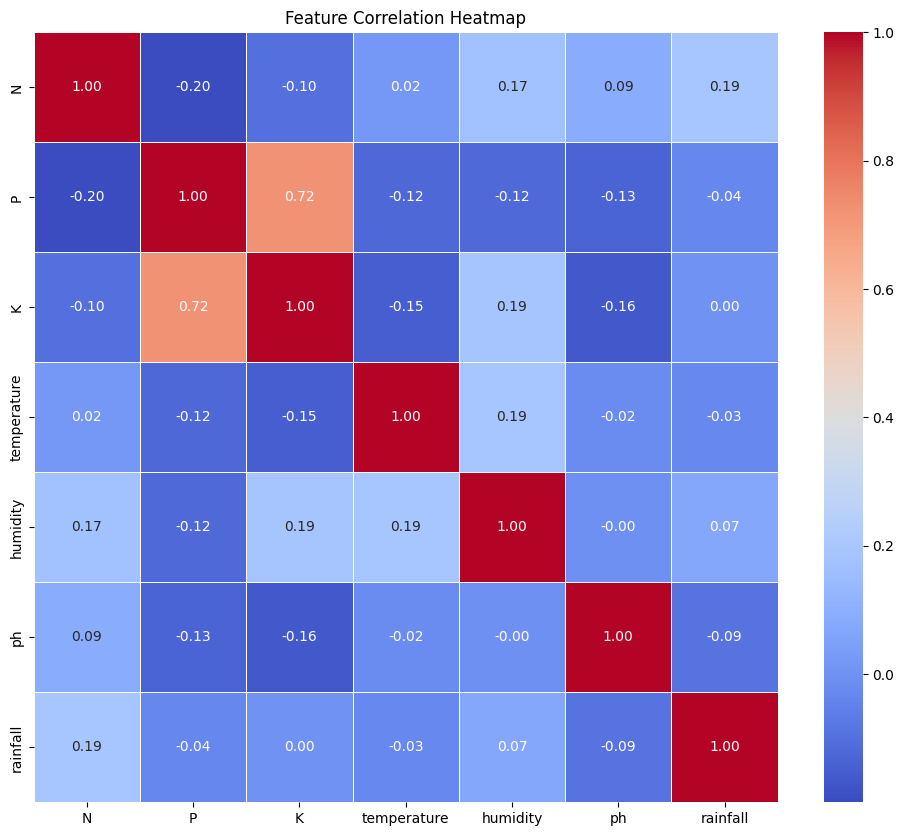

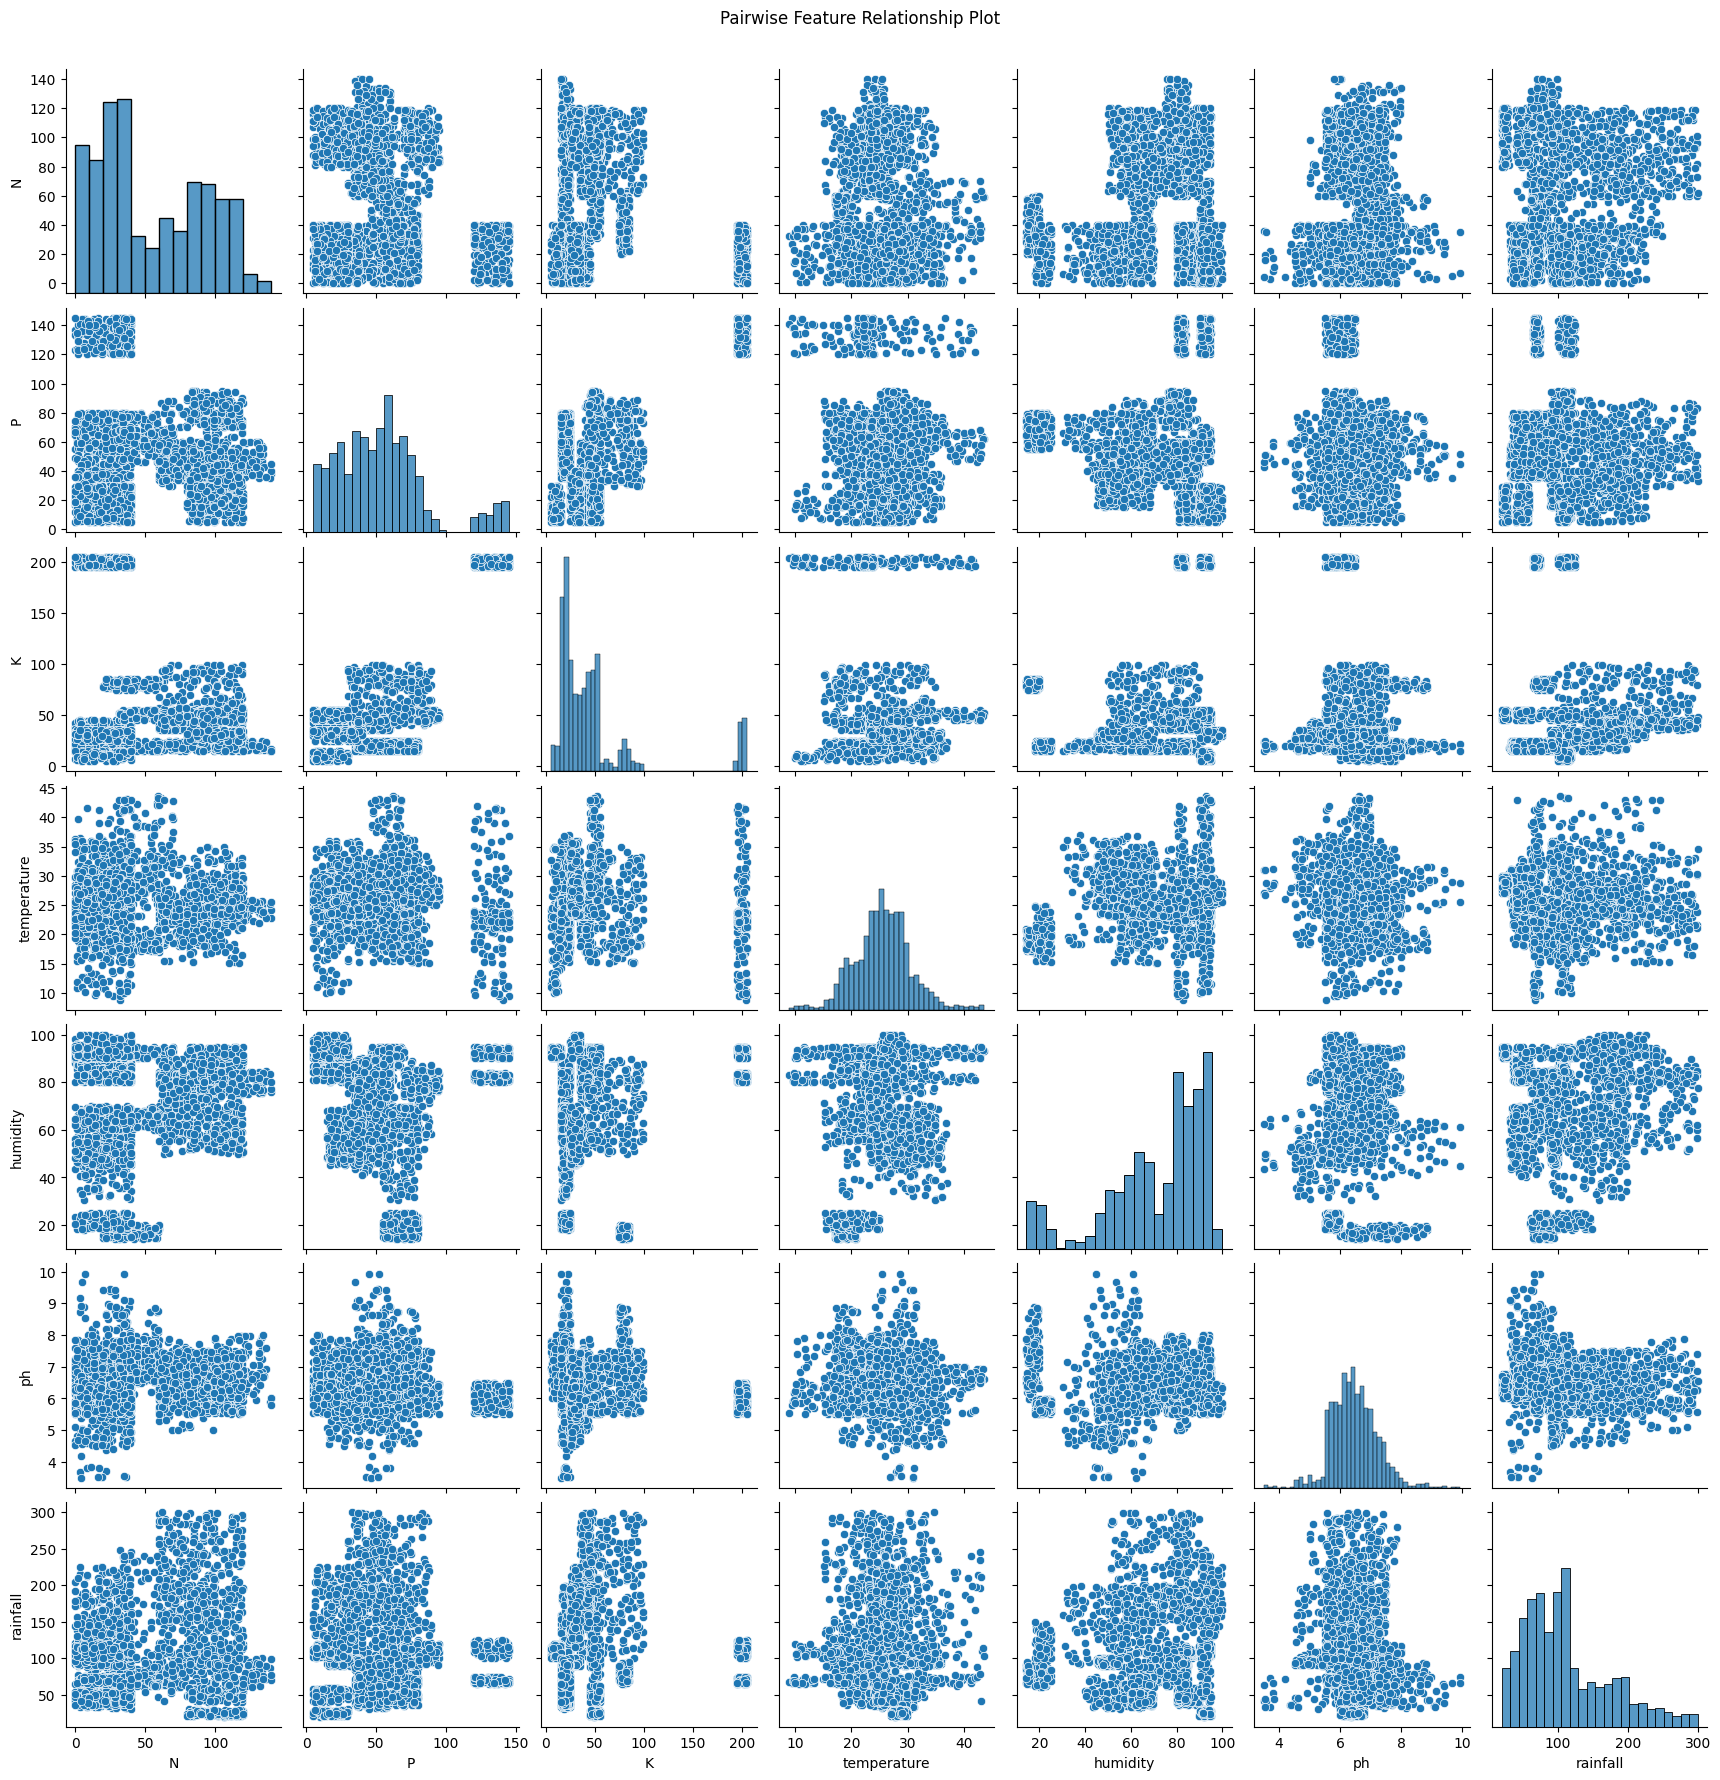

In [46]:
multivariate_processor = SimpleMultivariateStatisticalAnalysis()
selected_features = df[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']]
multivariate_processor.render(selected_features)

# Multivariate Analysis

## 1. Heatmap Correlation Insights

The correlation matrix provides insights into the relationships between different environmental factors affecting crop growth. Positive values indicate a direct relationship, whereas negative values suggest an inverse relationship.


### **1. Nitrogen (N) Relationships**
- **N vs Rainfall (0.19)**: Weak positive correlation; suggests that rainfall slightly influences nitrogen levels but not significantly.
- **N vs pH (0.09)**: Very weak correlation; nitrogen content is mostly independent of soil pH.
- **N vs Humidity (0.17)**: Weak positive relationship, indicating that nitrogen retention slightly improves with humidity.
- **N vs Temperature (0.02)**: Almost no correlation; nitrogen presence is unaffected by temperature.
- **N vs Potassium (-0.10)**: Slight negative correlation, implying that increasing potassium levels may reduce nitrogen availability.
- **N vs Phosphorus (-0.20)**: Moderate negative correlation, suggesting that phosphorus application might impact nitrogen retention in soil.

** Implication:**  
Nitrogen does not show strong dependence on environmental conditions, but phosphorus and potassium adjustments should be carefully managed to maintain nitrogen balance.


### **2. Phosphorus (P) Relationships**
- **P vs Rainfall (-0.04)**: Very weak negative correlation; phosphorus does not significantly depend on rainfall.
- **P vs pH (-0.13)**: Slightly negative correlation, indicating phosphorus solubility issues at different pH levels.
- **P vs Humidity (-0.12)**: Weak negative correlation, suggesting minor phosphorus depletion in humid conditions.
- **P vs Temperature (-0.12)**: Slight negative correlation; phosphorus levels tend to decrease in warmer conditions.
- **P vs Potassium (0.72)**: Strong positive correlation, meaning that phosphorus-rich soils also tend to have high potassium.

**Implication:**  
Phosphorus and potassium are highly interdependent, so fertilization strategies should optimize their combined application. Temperature and humidity management is essential to prevent phosphorus loss.


### **3. Potassium (K) Relationships**
- **K vs Rainfall (0.00)**: No correlation; potassium levels remain stable regardless of rainfall.
- **K vs pH (-0.16)**: Weak negative correlation; potassium absorption may decrease slightly in more acidic conditions.
- **K vs Humidity (0.19)**: Weak positive correlation; potassium might be better retained in humid conditions.
- **K vs Temperature (-0.15)**: Slight negative correlation, suggesting potassium depletion in higher temperatures.

**Implication:**  
Potassium is largely unaffected by external environmental factors except for its strong dependency on phosphorus. Managing pH is necessary to maintain optimal potassium uptake.


### **4. Temperature vs Other Factors**
- **Temperature vs Rainfall (-0.03)**: Very weak inverse correlation, meaning temperature variations have little impact on rainfall levels.
- **Temperature vs pH (-0.02)**: No meaningful correlation; temperature does not significantly affect soil pH.
- **Temperature vs Humidity (0.19)**: Weak positive correlation, meaning temperature slightly influences humidity levels.

**Implication:**  
While temperature and humidity have a weak correlation, they do not significantly influence other soil properties.


### **5. Humidity vs Other Factors**
- **Humidity vs Rainfall (0.07)**: Very weak positive correlation; humidity slightly increases with rainfall.
- **Humidity vs pH (-0.00)**: Almost no relationship, meaning soil pH remains stable despite humidity changes.

**Implication:**  
Humidity and rainfall do not strongly affect soil chemistry, but minor adjustments in irrigation may be needed to manage moisture levels for optimal growth.


### **6. pH vs Rainfall (-0.09)**
- Weak negative correlation suggests that rainfall slightly decreases soil pH, possibly due to leaching effects.


## **Key Takeaways**
- **Strongest Correlation:** **Phosphorus and Potassium (0.72)** → Their applications must be carefully balanced.
- **Weak but noticeable correlations:**
  - **Humidity and Nitrogen (0.17)** → Humid conditions may enhance nitrogen retention.
  - **Humidity and Potassium (0.19)** → Potassium retention slightly improves with humidity.
- **Almost No Effect:**  
  - Rainfall does not significantly influence soil nutrients.
  - Temperature has a minimal role in soil chemistry.



# Conclusion


## Insights from Univariate Analysis
- **Nitrogen (N):** Stable levels indicate consistent fertilizer use, with a critical role in leaf and stem growth.
- **Phosphorus (P):** Optimal range identified between 50-70, essential for root development.
- **Potassium (K):** Highly variable requirements, with some crops needing over 400 frequency for optimal growth.
- **Humidity & Temperature:** Specific ranges (e.g., 25-30°C and 80-100% humidity) were found to be optimal for most crops.
- **Rainfall:** Moderate levels (0-110 mm) were ideal, with higher levels leading to potential waterlogging.
- **pH:** Slightly acidic to neutral pH (5.5-7.0) was critical for nutrient absorption.

These insights highlighted the importance of each feature in crop growth but also revealed that no single factor could independently determine the best crop for a given condition.

## Insights from Bivariate Analysis
- **pH vs Nutrients:** Weak to moderate correlations were observed, with phosphorus and potassium showing a strong positive correlation (0.72).
- **Temperature vs Humidity:** A clear pattern emerged, with certain crops thriving in tightly coupled temperature and humidity ranges.
- **Rainfall vs Nutrients:** Rainfall showed minimal direct impact on nutrient levels but influenced overall crop suitability.

These relationships emphasized the interconnected nature of the features, suggesting that a model capable of capturing feature interactions would be essential.

## Insights from Multivariate Analysis
- **Feature Correlations:** Phosphorus and potassium were highly correlated, while nitrogen remained largely independent of other factors.
- **Complex Interactions:** Humidity and temperature had subtle but meaningful impacts on nutrient retention and crop growth.
- **Non-Linear Relationships:** Many relationships (e.g., pH vs nutrients) were non-linear, requiring a model that could handle such complexity.

## Why RandomForestClassifier?
Given the above insights, the **RandomForestClassifier** was chosen for the following reasons:

1. **Handles Non-Linear Relationships:**  
   The analysis revealed that crop growth depends on complex, non-linear interactions between features. Random Forest excels at capturing such relationships through its ensemble of decision trees.

2. **Feature Importance:**  
   The model provides a clear measure of feature importance, aligning with the need to prioritize key factors like nitrogen, phosphorus, and potassium, as identified in the analysis.

3. **Robust to Outliers and Noise:**  
   The dataset contained variability (e.g., crops with extreme potassium requirements), and Random Forest's ensemble approach ensures robustness against such anomalies.

4. **Captures Feature Interactions:**  
   The strong correlation between phosphorus and potassium, as well as the subtle influence of humidity on nitrogen, highlighted the importance of modeling feature interactions. Random Forest inherently accounts for these interactions.

5. **Scalability and Interpretability:**  
   With multiple features (N, P, K, temperature, humidity, pH, rainfall), Random Forest scales well and provides interpretable results, making it easier to derive actionable insights for farmers.

The **RandomForestClassifier** was selected as the optimal modeling technique because it aligns perfectly with the insights derived from the univariate, bivariate, and multivariate analyses. Its ability to handle complex relationships, prioritize key features, and provide robust predictions makes it the ideal choice for building a crop recommendation system.